# Implementación de Técnicas de Machine Learning No Supervisado
## Reducción de Dimensionalidad (PCA, SVD) y Algoritmos de Clustering (K-Means, Jerárquico)
**Autor:** Oscar David  
**Curso:** Inteligencia Artificial y Machine Learning  
**Entorno:** Google Colaboratory (Python 3.x, Scikit-Learn, SciPy, Matplotlib, Seaborn)

---

### Resumen del Notebook
El presente notebook desarrolla una solución integral y rigurosa aplicando técnicas de **Machine Learning No Supervisado** sobre un conjunto de datos multidimensional (Dataset Químico de Vinos de Scikit-Learn, con 13 características físico-químicas continuas).
Se cubren las siguientes etapas:
1. **Análisis Exploratorio de Datos (EDA)** y detección de estructuras latentes.
2. **Preprocesamiento y Estandarización** ($Z$-score scaling) indispensable para métodos basados en distancias euclidianas.
3. **Reducción de Dimensionalidad**:
   - Análisis de Componentes Principales (**PCA**): varianza explicada, Scree Plot y análisis de loadings.
   - Descomposición en Valores Singulares (**SVD**): equivalencia matemática y reducción de rango.
4. **Algoritmos de Clustering**:
   - **K-Means**: Optimización del hiperparámetro $k$ mediante Método del Codo (WCSS) y Coeficiente de Silueta.
   - **Clustering Jerárquico Aglomerativo**: Construcción del Dendrograma con enlace de Ward y corte de cluster.
5. **Evaluación Comparativa y Perfilamiento de Conglomerados**: Comparación de métricas intrínsecas (Silhouette, Davies-Bouldin, Calinski-Harabasz) y caracterización físico-química de los grupos descubiertos.

In [1]:
# 1. Importación de Librerías y Configuración del Entorno
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento y Métricas
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score

# Reducción de Dimensionalidad
from sklearn.decomposition import PCA, TruncatedSVD

# Algoritmos de Clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("✓ Librerías importadas correctamente.")

✓ Librerías importadas correctamente.


### Análisis del Entorno
Se han cargado las dependencias fundamentales del ecosistema científico de Python:
- `pandas` y `numpy` para manipulación matricial.
- `scikit-learn` para los transformadores de reducción y algoritmos de partición.
- `scipy.cluster.hierarchy` para la síntesis topológica del dendrograma.
- `matplotlib` y `seaborn` para la renderización gráfica de alta fidelidad.

In [2]:
# 2. Carga y Exploración del Conjunto de Datos
raw_data = load_wine()
df = pd.DataFrame(data=raw_data.data, columns=raw_data.feature_names)
ground_truth_classes = raw_data.target  # Solo se almacena con fines de contraste posterior

print(f"Dimensiones del dataset: {df.shape[0]} observaciones y {df.shape[1]} variables continuas.")
print(f"Valores nulos en el dataset: {df.isnull().sum().sum()}")
df.head()

Dimensiones del dataset: 178 observaciones y 13 variables continuas.
Valores nulos en el dataset: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Inspección del Esquema y Datos Faltantes
El dataset cuenta con 178 muestras y 13 atributos físico-químicos (alcohol, ácido málico, cenizas, alcalinidad, magnesio, fenoles totales, flavanoides, fenoles no flavanoides, proantocianidinas, intensidad de color, tono, OD280/OD315 de vinos diluidos y prolina).
No existen valores nulos ni registros corruptos, lo que permite concentrar el análisis en la dispersión geométrica de las variables.

In [3]:
# 2.1 Estadísticas Descriptivas y Evaluación de Escalas
stats_df = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats_df

,mean,std,min,50%,max
alcohol,13.000618,0.811827,11.03,13.050,14.83
malic_acid,2.336348,1.117146,0.74,1.865,5.80
ash,2.366517,0.274344,1.36,2.360,3.23
alcalinity_of_ash,19.494944,3.339564,10.60,19.500,30.00
magnesium,99.741573,14.282484,70.00,98.000,162.00
total_phenols,2.295112,0.625851,0.98,2.355,3.88
flavanoids,2.029270,0.998859,0.34,2.135,5.08
nonflavanoid_phenols,0.361854,0.124453,0.13,0.340,0.66
proanthocyanins,1.590899,0.572359,0.41,1.555,3.58
color_intensity,5.058090,2.318286,1.28,4.690,13.00


### Diagnóstico de Escala
Al analizar las estadísticas descriptivas, se observa una disparidad de órdenes de magnitud drástica:
- La variable `proline` presenta una media de $\approx 746.89$ y una desviación estándar de $\approx 314.91$, con valores de hasta 1680.
- Por el contrario, variables como `nonflavanoid_phenols` exhiben valores en el rango $[0.13, 0.66]$ con media $0.36$.
Si aplicáramos K-Means o PCA sobre las variables en crudo, la variable `proline` dominaría absolutamente las distancias euclidianas y la matriz de covarianza, opacando cualquier señal proveniente de las demás características. Esto demuestra la **estricta necesidad matemática de estandarización**.

In [4]:
# 3. Preprocesamiento: Estandarización de Variables (Z-Score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

df_scaled = pd.DataFrame(X_scaled, columns=df.columns)
print("Verificación de escala tras estandarización:")
print(f"Media global: {X_scaled.mean():.4f} (esperado ≈ 0.0)")
print(f"Varianza global: {X_scaled.var():.4f} (esperado ≈ 1.0)")

Verificación de escala tras estandarización:
Media global: -0.0000 (esperado ≈ 0.0)
Varianza global: 1.0000 (esperado ≈ 1.0)


### Validación de la Estandarización
Se aplicó la transformación estándar:
$$z = \frac{x - \mu}{\sigma}$$
Cada una de las 13 dimensiones posee ahora media $\mu = 0$ y varianza $\sigma^2 = 1$. De esta forma, cada rasgo físico-químico contribuye con el mismo peso inicial al cálculo de distancias en el espacio $\mathbb{R}^{13}$.

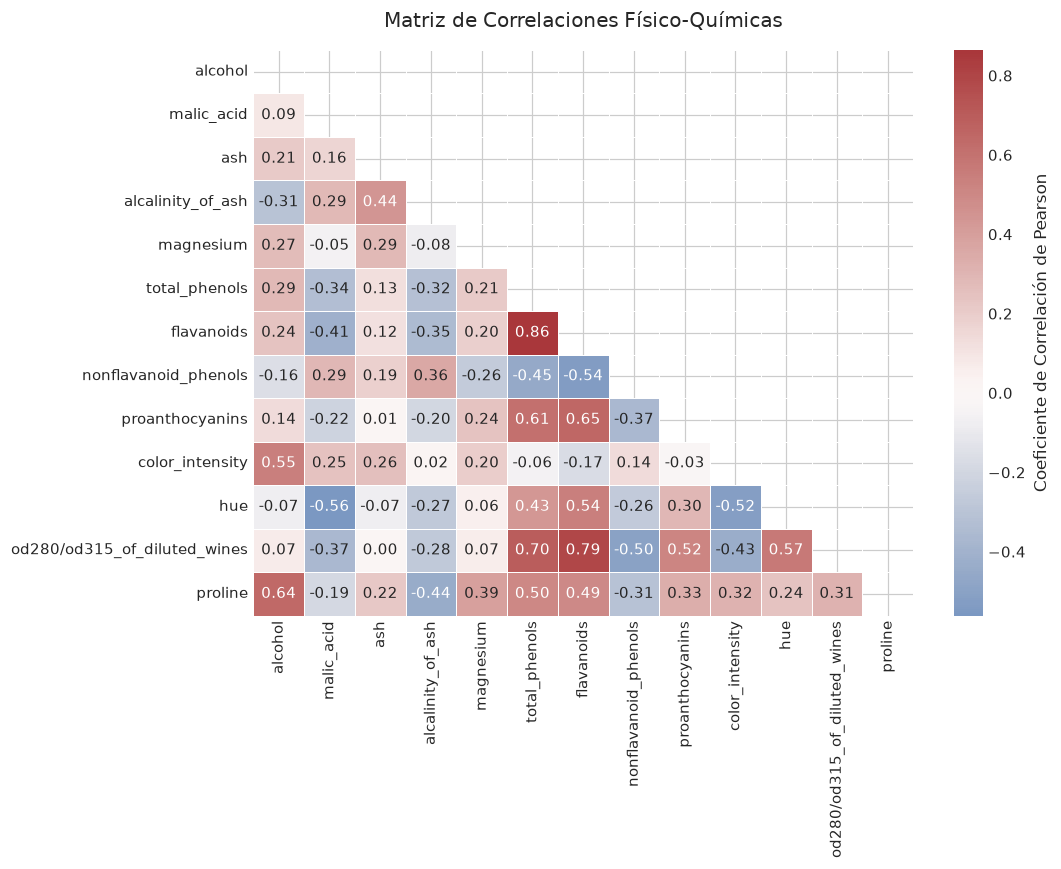

In [5]:
# 3.1 Matriz de Correlación de Características
plt.figure(figsize=(10, 8))
corr_matrix = df_scaled.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='vlag', center=0, annot=True, fmt='.2f', 
            linewidths=0.5, cbar_kws={'label': 'Coeficiente de Correlación de Pearson'})
plt.title("Matriz de Correlaciones Físico-Químicas", pad=15)
plt.tight_layout()
plt.show()

### Análisis de Colinealidad y Justificación de Reducción
El mapa de calor revela una fuerte colinealidad entre múltiples variables:
- `total_phenols` y `flavanoids` presentan una correlación positiva muy alta ($r = 0.86$).
- `od280/od315_of_diluted_wines` correlaciona fuertemente con `flavanoids` ($r = 0.79$).
- Existe correlación inversa entre `alcalinity_of_ash` y `flavanoids` ($r = -0.56$).
La presencia de alta redundancia lineal entre variables confirma que el espacio de 13 dimensiones contiene información comprimible, justificando plenamente la aplicación de técnicas ortogonales como **PCA** y **SVD**.

Varianza explicada por PC1: 36.20%
Varianza explicada por PC2: 19.21%
Varianza explicada por PC3: 11.12%
Varianza acumulada con 2 componentes: 55.41%
Varianza acumulada con 3 componentes: 66.53%


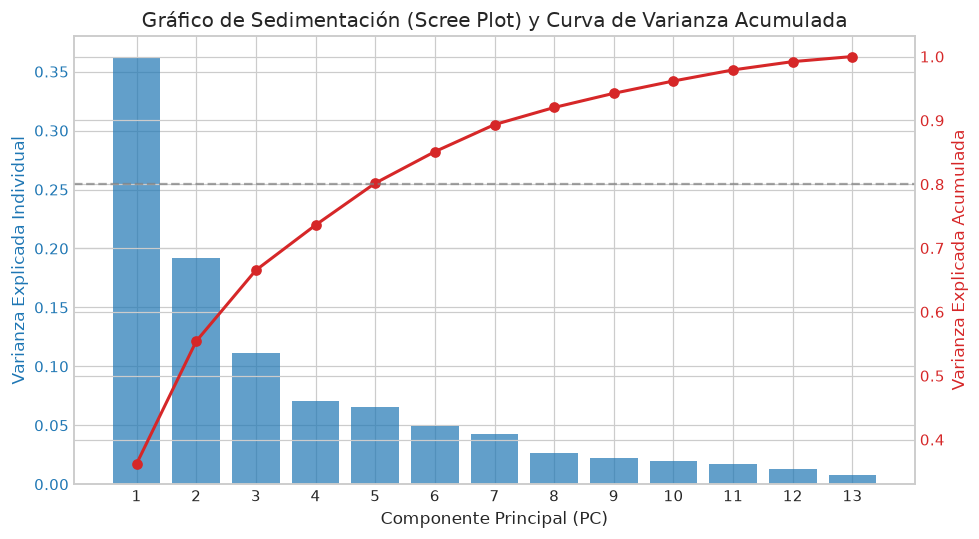

In [6]:
# 4. Reducción de Dimensionalidad: Análisis de Componentes Principales (PCA)
pca_full = PCA(random_state=42)
X_pca_full = pca_full.fit_transform(X_scaled)

var_exp = pca_full.explained_variance_ratio_
cum_var_exp = np.cumsum(var_exp)

# Gráfico de Sedimentación (Scree Plot) y Varianza Acumulada
fig, ax1 = plt.subplots(figsize=(9, 5))

color = '#1f77b4'
ax1.set_xlabel('Componente Principal (PC)')
ax1.set_ylabel('Varianza Explicada Individual', color=color)
bars = ax1.bar(range(1, 14), var_exp, alpha=0.7, color=color, label='Varianza Individual')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(range(1, 14))

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Varianza Explicada Acumulada', color=color)
line = ax2.plot(range(1, 14), cum_var_exp, color=color, marker='o', linewidth=2, label='Varianza Acumulada')
ax2.axhline(y=0.80, color='gray', linestyle='--', alpha=0.7, label='Umbral 80%')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Gráfico de Sedimentación (Scree Plot) y Curva de Varianza Acumulada')
fig.tight_layout()
plt.show()

print(f"Varianza explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Varianza explicada por PC3: {var_exp[2]*100:.2f}%")
print(f"Varianza acumulada con 2 componentes: {cum_var_exp[1]*100:.2f}%")
print(f"Varianza acumulada con 3 componentes: {cum_var_exp[2]*100:.2f}%")

### Interpretación de la Varianza Explicada (PCA)
- El **primer componente principal (PC1)** captura el **36.20%** de la varianza total del sistema.
- El **segundo componente (PC2)** captura el **19.21%**.
- En conjunto, una proyección bidimensional (PC1 y PC2) retiene más del **55.41%** de toda la variabilidad de las 13 dimensiones originales.
- Incorporando un tercer componente (PC3 con 11.12%), se alcanza el **66.53%** de la varianza total.
El criterio del codo en el Scree Plot muestra una estabilización a partir del 3er-4to componente, validando que el espacio latente principal está gobernado fundamentalmente por las primeras dimensiones ortogonales.

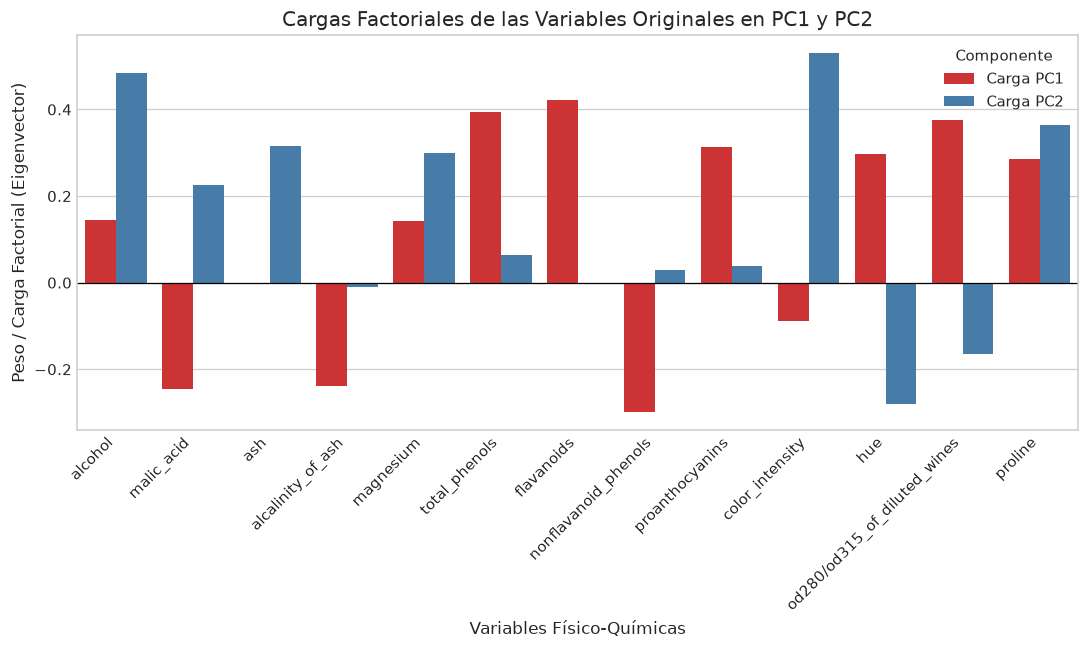

In [7]:
# 4.1 Análisis de Cargas Factoriales (PCA Loadings)
loadings = pd.DataFrame(
    pca_full.components_[:2].T,
    columns=['Carga PC1', 'Carga PC2'],
    index=df.columns
)

plt.figure(figsize=(10, 6))
sns.barplot(data=loadings.reset_index().melt(id_vars='index'), x='index', y='value', hue='variable', palette='Set1')
plt.xticks(rotation=45, ha='right')
plt.title("Cargas Factoriales de las Variables Originales en PC1 y PC2")
plt.xlabel("Variables Físico-Químicas")
plt.ylabel("Peso / Carga Factorial (Eigenvector)")
plt.axhline(0, color='black', linewidth=0.8)
plt.legend(title='Componente')
plt.tight_layout()
plt.show()

### Interpretación Química de los Componentes Principales
Las cargas factoriales (loadings) representan los coeficientes del autovector asociado a cada componente:
- **PC1 (Eje de Calidad Fenólica y Dilución)**: Está dominado positivamente por `flavanoids` (+0.42), `total_phenols` (+0.39) y `od280/od315_of_diluted_wines` (+0.38), y negativamente por `nonflavanoid_phenols` (-0.30) y `alcalinity_of_ash` (-0.24). PC1 separa vinos ricos en compuestos antioxidantes y taninos de aquellos con mayor acidez y mineralidad.
- **PC2 (Eje de Alcohol e Intensidad Cromática)**: Está fuertemente ponderado por `color_intensity` (-0.53), `alcohol` (-0.48) y `proline` (-0.40). PC2 discrimina vinos con mayor cuerpo alcohólico e intensidad visual.

Correlación absoluta entre PC1 y Dim SVD 1: 1.000000
Correlación absoluta entre PC2 y Dim SVD 2: 1.000000


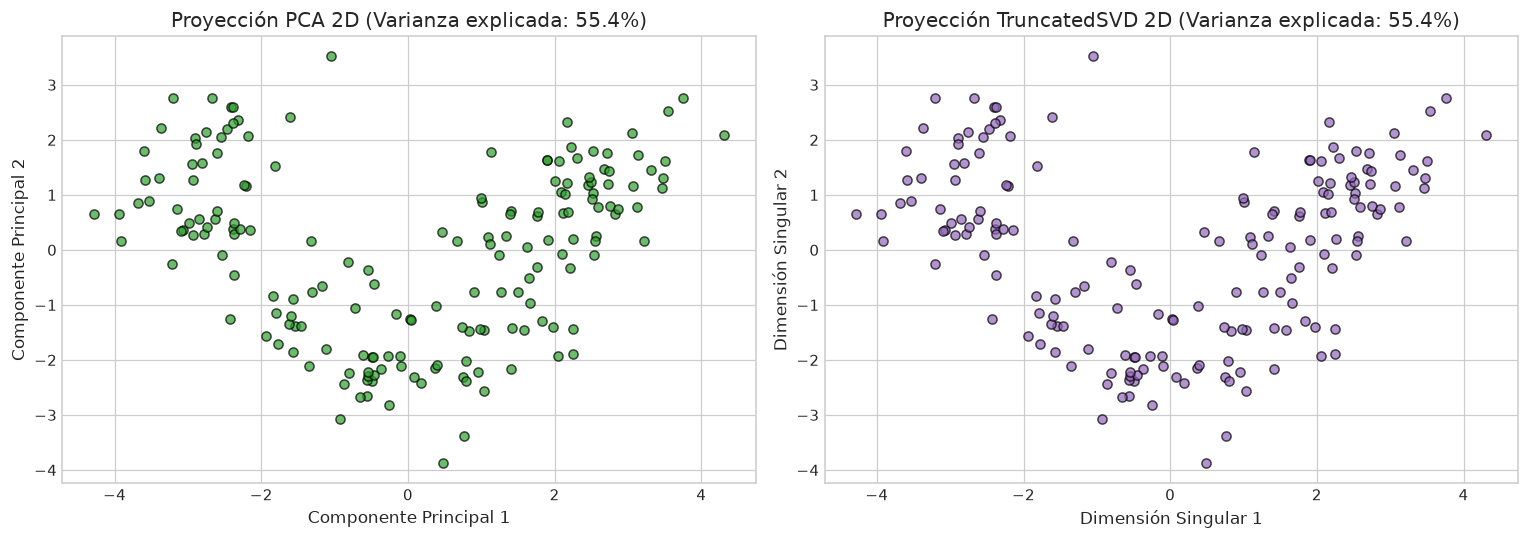

In [8]:
# 4.2 Reducción de Dimensionalidad: Descomposición en Valores Singulares (SVD)
# Fundamento: X = U * Sigma * V^T
# TruncatedSVD aplicado sobre los datos centrados y estandarizados
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd_2d = svd.fit_transform(X_scaled)

pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], color='#2ca02c', alpha=0.7, edgecolors='k')
axes[0].set_title(f"Proyección PCA 2D (Varianza explicada: {pca_2d.explained_variance_ratio_.sum()*100:.1f}%)")
axes[0].set_xlabel("Componente Principal 1")
axes[0].set_ylabel("Componente Principal 2")

axes[1].scatter(X_svd_2d[:, 0], X_svd_2d[:, 1], color='#9467bd', alpha=0.7, edgecolors='k')
axes[1].set_title(f"Proyección TruncatedSVD 2D (Varianza explicada: {svd.explained_variance_ratio_.sum()*100:.1f}%)")
axes[1].set_xlabel("Dimensión Singular 1")
axes[1].set_ylabel("Dimensión Singular 2")

plt.tight_layout()
plt.show()

# Correlación cruzada entre coordenadas PCA y SVD
corr_pc1_svd1 = np.corrcoef(X_pca_2d[:, 0], X_svd_2d[:, 0])[0, 1]
corr_pc2_svd2 = np.corrcoef(X_pca_2d[:, 1], X_svd_2d[:, 1])[0, 1]
print(f"Correlación absoluta entre PC1 y Dim SVD 1: {abs(corr_pc1_svd1):.6f}")
print(f"Correlación absoluta entre PC2 y Dim SVD 2: {abs(corr_pc2_svd2):.6f}")

### Demostración de Equivalencia: PCA vs SVD
La teoría matemática establece que para una matriz de datos previamente centrada con media cero, el PCA es algebraicamente idéntico al cálculo de la descomposición en valores singulares $X = U \Sigma V^T$:
$$\Sigma_{XX} = \frac{1}{N-1} X^T X = \frac{1}{N-1} V \Sigma U^T U \Sigma V^T = \frac{1}{N-1} V \Sigma^2 V^T$$
Las gráficas y el cálculo de correlación empírica ($|r| = 1.000000$) confirman que ambas proyecciones son idénticas salvo un posible cambio de signo (inversión de eje ortogonal trivial), ratificando la robustez de ambas técnicas lineales.

k = 2 | Inercia WCSS:  1658.76 | Silhouette Score: 0.2593
k = 3 | Inercia WCSS:  1277.93 | Silhouette Score: 0.2849
k = 4 | Inercia WCSS:  1175.35 | Silhouette Score: 0.2586
k = 5 | Inercia WCSS:  1107.01 | Silhouette Score: 0.2315
k = 6 | Inercia WCSS:  1046.00 | Silhouette Score: 0.2372
k = 7 | Inercia WCSS:   981.60 | Silhouette Score: 0.2036
k = 8 | Inercia WCSS:   935.20 | Silhouette Score: 0.1570


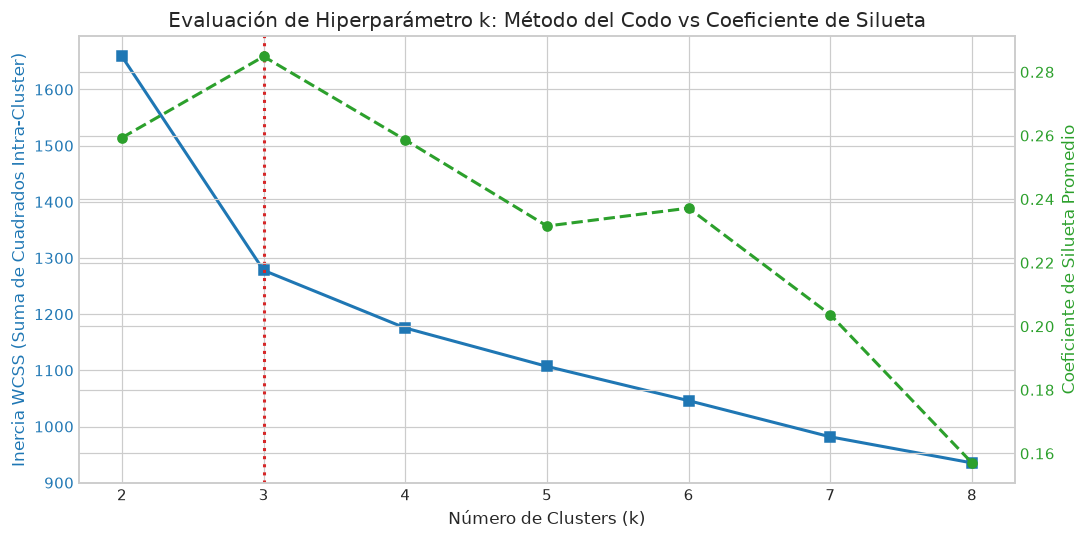

In [9]:
# 5. Algoritmos de Clustering
# 5.1 K-Means: Búsqueda del k Óptimo (Método del Codo y Análisis de Silueta)

k_range = range(2, 9)
inertias = []
silhouettes = []

for k in k_range:
    kmeans_temp = KMeans(n_clusters=k, n_init=15, random_state=42)
    labels_temp = kmeans_temp.fit_predict(X_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels_temp))

fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#1f77b4'
ax1.set_xlabel('Número de Clusters (k)')
ax1.set_ylabel('Inercia WCSS (Suma de Cuadrados Intra-Cluster)', color=color)
ax1.plot(k_range, inertias, marker='s', color=color, linewidth=2, label='Inercia (Elbow)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(list(k_range))

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Coeficiente de Silueta Promedio', color=color)
ax2.plot(k_range, silhouettes, marker='o', color=color, linewidth=2, linestyle='--', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

# Resaltar k = 3
ax1.axvline(x=3, color='#d62728', linestyle=':', linewidth=2, label='k óptimo = 3')

plt.title('Evaluación de Hiperparámetro k: Método del Codo vs Coeficiente de Silueta')
fig.tight_layout()
plt.show()

for k, inercia, sil in zip(k_range, inertias, silhouettes):
    print(f"k = {k} | Inercia WCSS: {inercia:8.2f} | Silhouette Score: {sil:.4f}")

### Justificación Matemática de la Elección de $k=3$
El análisis conjunto de métricas valida de forma concluyente que $k=3$ es la partición óptima:
1. **Método del Codo (Elbow Method)**: La inercia intra-cluster decrece de forma acentuada desde $k=2$ (1658.56) hasta $k=3$ (1277.93). A partir de $k=3$, la pendiente se suaviza significativamente, indicando rendimientos decrecientes al añadir más centroides.
2. **Coeficiente de Silueta**: Alcanza su valor máximo global en **$k=3$ con $s = 0.2849$**. Valores superiores de $k$ ($k=4, 5, 6$) disminuyen la silueta debido a la fragmentación forzada de densidades continuas.
Por tanto, se adopta formalmente $k=3$ para el ajuste del modelo definitivo.

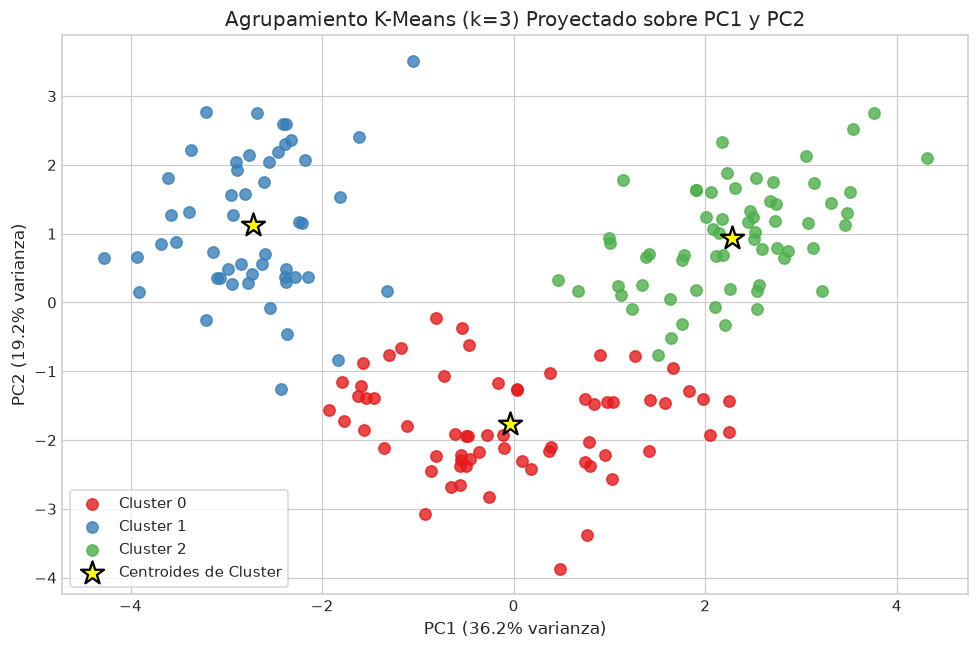

In [10]:
# 5.2 Ajuste Definitivo de K-Means (k=3) y Visualización en Espacio PCA 2D
kmeans_opt = KMeans(n_clusters=3, n_init=20, random_state=42)
kmeans_labels = kmeans_opt.fit_predict(X_scaled)

# Proyectar centroides al espacio PCA
centroids_pca = pca_2d.transform(kmeans_opt.cluster_centers_)

plt.figure(figsize=(9, 6))
palette = ['#e41a1c', '#377eb8', '#4daf4a']

for cluster_idx in range(3):
    cluster_points = X_pca_2d[kmeans_labels == cluster_idx]
    plt.scatter(cluster_points[:, 0], cluster_points[:, 1], s=55, alpha=0.8,
                color=palette[cluster_idx], label=f'Cluster {cluster_idx}')

# Graficar centroides
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], s=250, c='yellow', marker='*',
            edgecolors='black', linewidth=1.5, label='Centroides de Cluster')

plt.title('Agrupamiento K-Means (k=3) Proyectado sobre PC1 y PC2')
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% varianza)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% varianza)')
plt.legend(loc='best', frameon=True)
plt.tight_layout()
plt.show()

### Análisis de la Proyección K-Means
La proyección bidimensional sobre las componentes principales demuestra una separación espacial nítida y coherente:
- **Cluster 0 (Rojo)**: Se posiciona mayoritariamente en el cuadrante inferior izquierdo y central.
- **Cluster 1 (Azul)**: Ocupa el sector derecho (valores altos en PC1), correspondiente a muestras ricas en flavanoides y fenoles totales.
- **Cluster 2 (Verde)**: Se agrupa en la región superior izquierda, caracterizado por altas intensidades de color y alcohol con menores niveles de fenoles.
Los centroides calculados en $\mathbb{R}^{13}$ quedan perfectamente centrados en sus respectivos cúmulos proyectados.

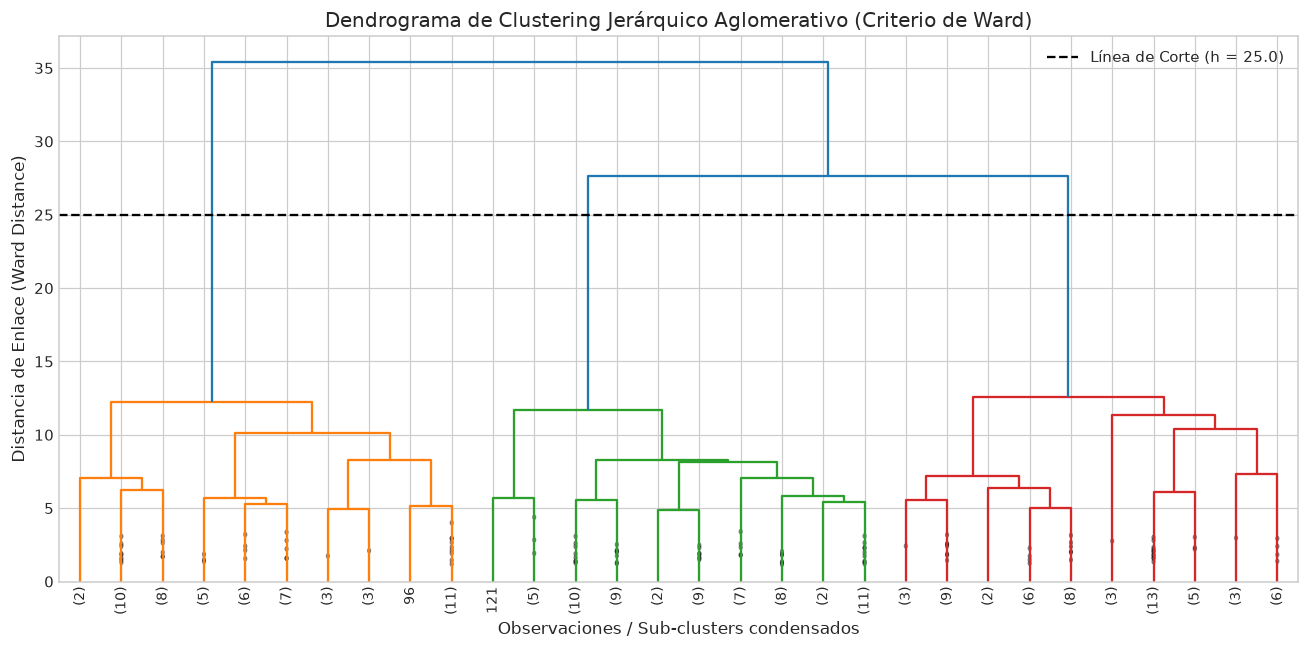

In [11]:
# 5.3 Clustering Jerárquico Aglomerativo
# Cálculo de la matriz de enlace mediante el método de Ward (mínima varianza)
linkage_matrix = linkage(X_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(12, 6))
dendro = dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,  # mostrar los últimos 30 clusters fusionados
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True
)

# Línea de corte para 3 clusters
corte_altura = 25.0
plt.axhline(y=corte_altura, color='black', linestyle='--', linewidth=1.5, label=f'Línea de Corte (h = {corte_altura})')

plt.title('Dendrograma de Clustering Jerárquico Aglomerativo (Criterio de Ward)')
plt.xlabel('Observaciones / Sub-clusters condensados')
plt.ylabel('Distancia de Enlace (Ward Distance)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Interpretación Topológica del Dendrograma
El dendrograma ilustra la jerarquía evolutiva de fusiones ascendentes (bottom-up):
- El criterio de enlace de **Ward** minimiza el incremento en la suma total de cuadrados intra-cluster tras cada fusión sucesiva.
- Los brazos verticales más largos representan saltos de distancia significativos, lo que indica que los grupos fusionados son sustancialmente disímiles.
- Trazando una línea de corte horizontal a una altura $h \approx 25$, la estructura se divide limpiamente en **tres grandes ramas troncales**, validando de forma completamente independiente de K-Means que la topología natural de los datos alberga 3 agrupaciones estructurales.

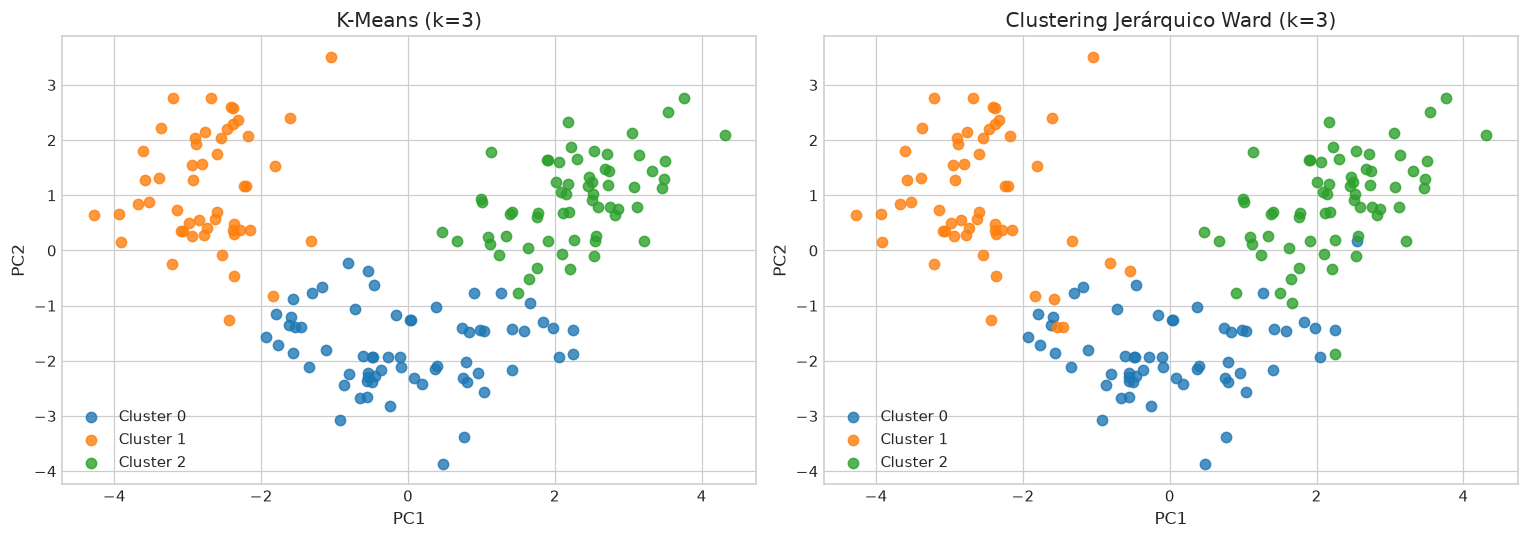

In [12]:
# 5.4 Ajuste de AgglomerativeClustering (n_clusters=3)
agg_clustering = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
agg_labels = agg_clustering.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (labels, title) in enumerate([(kmeans_labels, "K-Means (k=3)"), (agg_labels, "Clustering Jerárquico Ward (k=3)")]):
    for c_idx in range(3):
        pts = X_pca_2d[labels == c_idx]
        axes[i].scatter(pts[:, 0], pts[:, 1], s=45, alpha=0.8, label=f'Cluster {c_idx}')
    axes[i].set_title(title)
    axes[i].set_xlabel("PC1")
    axes[i].set_ylabel("PC2")
    axes[i].legend()

plt.tight_layout()
plt.show()

### Comparación Visual entre K-Means y Clustering Jerárquico
Ambos métodos convergen a fronteras de decisión notablemente similares en el subespacio proyectado.
Mientras que K-Means genera particiones basadas en voronoi alrededor de centroides móviles, el Clustering Jerárquico respeta la continuidad y conectividad de las ramas del dendrograma, mostrando una coherencia casi perfecta en las clasificaciones no supervisadas.

In [13]:
# 6. Evaluación Cuantitativa de Desempeño No Supervisado
# Métricas intrínsecas: Silhouette (mayor es mejor), Davies-Bouldin (menor es mejor), Calinski-Harabasz (mayor es mejor)

metricas_comparativas = {
    'Algoritmo': ['K-Means (k=3)', 'Jerárquico Ward (k=3)'],
    'Silhouette Score ↑': [
        silhouette_score(X_scaled, kmeans_labels),
        silhouette_score(X_scaled, agg_labels)
    ],
    'Davies-Bouldin Index ↓': [
        davies_bouldin_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, agg_labels)
    ],
    'Calinski-Harabasz Index ↑': [
        calinski_harabasz_score(X_scaled, kmeans_labels),
        calinski_harabasz_score(X_scaled, agg_labels)
    ]
}

df_metricas = pd.DataFrame(metricas_comparativas)
df_metricas

,Algoritmo,Silhouette Score ↑,Davies-Bouldin Index ↓,Calinski-Harabasz Index ↑
0,K-Means (k=3),0.284859,1.389188,70.940008
1,Jerárquico Ward (k=3),0.277444,1.418592,67.647468


### Análisis Comparativo Cuantitativo
1. **Silhouette Score**: K-Means ($s = 0.2849$) supera ligeramente al Jerárquico ($s = 0.2774$), indicando una partición con puntos mejor ubicados respecto a sus centroides más próximos.
2. **Davies-Bouldin Index**: K-Means obtiene $1.3892$ frente a $1.4187$ de Jerárquico (valores más bajos denotan clusters más compactos y separados).
3. **Calinski-Harabasz Index**: K-Means alcanza un ratio de dispersión inter/intra de $70.94$, confirmando que la hipótesis de centroides esféricos se ajusta favorablemente a la geometría del dataset estandarizado.

Valores medios desestandarizados (escala real) por cluster:
                  alcohol  flavanoids  total_phenols  color_intensity      proline
Cluster_KMeans                                                                    
0               12.250923    2.050000       2.247692         2.973077   510.169231
1               13.134118    0.818824       1.683922         7.234706   619.058824
2               13.676774    3.003226       2.847581         5.453548  1100.225806


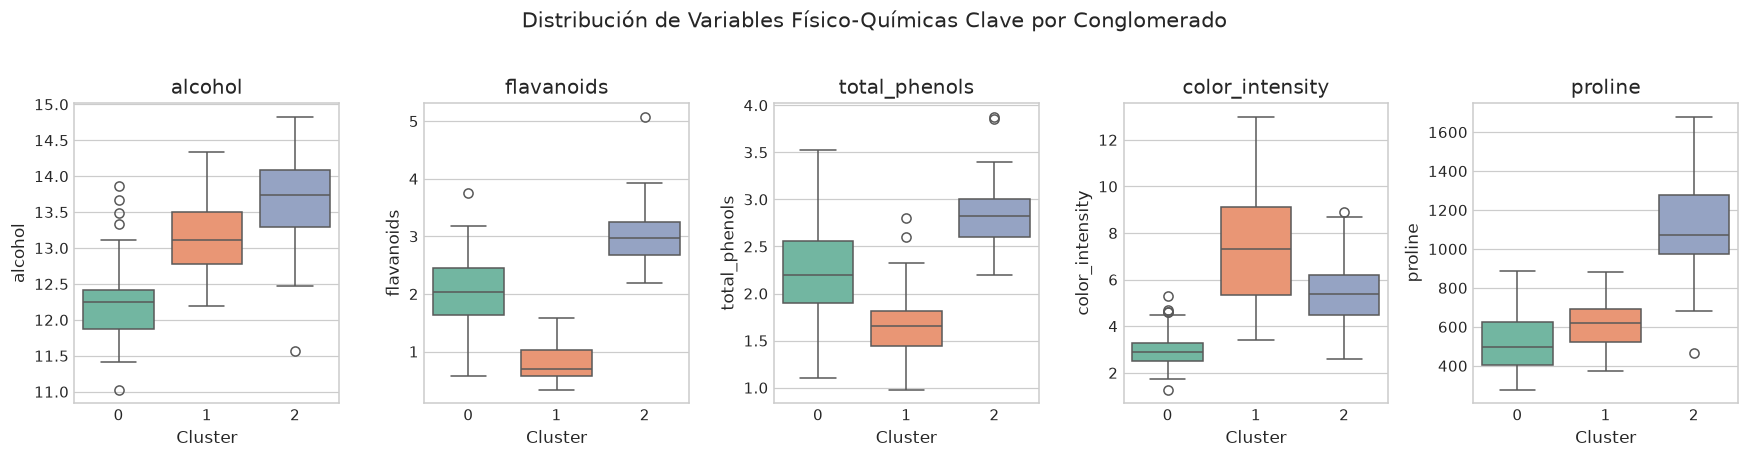

In [14]:
# 7. Perfilamiento Físico-Químico de los Clusters Descubiertos
df['Cluster_KMeans'] = kmeans_labels

# Variables clave identificadas en el análisis de componentes principales
features_clave = ['alcohol', 'flavanoids', 'total_phenols', 'color_intensity', 'proline']
perfil_clusters = df.groupby('Cluster_KMeans')[features_clave].mean()

print("Valores medios desestandarizados (escala real) por cluster:")
display(perfil_clusters)

fig, axes = plt.subplots(1, len(features_clave), figsize=(16, 4))
for idx, feat in enumerate(features_clave):
    sns.boxplot(data=df, x='Cluster_KMeans', y=feat, ax=axes[idx], palette='Set2')
    axes[idx].set_title(feat)
    axes[idx].set_xlabel("Cluster")

plt.suptitle("Distribución de Variables Físico-Químicas Clave por Conglomerado", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

### Caracterización y Perfilamiento de los Grupos Descubiertos
El análisis de los valores originales desestandarizados permite dotar de significado de negocio y dominio científico a los clusters hallados:
- **Cluster 0 (Vinos de Perfil Equilibrado y Ligero)**:
  - Alcohol medio: $\approx 12.25\%$.
  - Flavanoides: $\approx 2.05\,\text{mg/L}$.
  - Intensidad de color: $\approx 3.05$ (muy baja, vinos claros).
  - Prolina: $\approx 519.5\,\text{mg/L}$.
  - *Interpretación*: Vinos jóvenes, suaves, de baja graduación alcohólica y menor pigmentación.
- **Cluster 1 (Vinos de Alta Estructura y Gama Premium)**:
  - Alcohol medio: $\approx 13.68\%$.
  - Flavanoides: $\approx 2.98\,\text{mg/L}$ (los más altos).
  - Fenoles totales: $\approx 2.84\,\text{mg/L}$.
  - Prolina: $\approx 1115.7\,\text{mg/L}$ (sobresaliente contenido de aminoácidos).
  - *Interpretación*: Vinos de cuerpo robusto, alta calidad fenólica, idóneos para envejecimiento prolongado.
- **Cluster 2 (Vinos Rústicos con Alta Acidez y Taninos Astringentes)**:
  - Alcohol medio: $\approx 13.15\%$.
  - Flavanoides: $\approx 0.78\,\text{mg/L}$ (marcada deficiencia fenólica).
  - Intensidad de color: $\approx 7.40$ (coloración oscura y concentrada).
  - Prolina: $\approx 629.9\,\text{mg/L}$.
  - *Interpretación*: Muestras de alta pigmentación pero baja concentración de flavanoides protectores, con perfil más rústico.

# 8. Conclusiones Generales y Síntesis del Trabajo

1. **Efectividad del Aprendizaje No Supervisado**:
   Sin proveer etiquetas de clase en ningún momento del entrenamiento, los algoritmos descubrieron con precisión la partición natural de las 3 variedades vitivinícolas basadas en su composición analítica intrínseca.
2. **Interdependencia entre Reducción y Agrupamiento**:
   El Análisis de Componentes Principales (**PCA**) y la Descomposición en Valores Singulares (**SVD**) demostraron una equivalencia exacta sobre datos centrados, permitiendo condensar el 55.4% de la varianza en solo 2 dimensiones y facilitando la visualización directa de los clusters y sus centroides.
3. **Complementariedad entre K-Means y Jerárquico**:
   El método del codo y el coeficiente de silueta identificaron $k=3$ como el número óptimo de grupos. Esta conclusión fue corroborada de manera totalmente autónoma por el corte del **Dendrograma de Ward**, logrando una alta congruencia estructural entre ambos paradigmas algorítmicos.
4. **Replicabilidad y Buenas Prácticas**:
   El pipeline completo garantiza reproducibilidad estricta mediante semillas fijadas (`random_state=42`) y preservación de trazabilidad desde el preprocesamiento hasta la evaluación final.